# Übung 03 : Stochastische Grundlagen

Wie üblich importieren wir zuerst unsere Standardbibliotheken

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## Aufgabe 1: Korrelation
Lade die als *.npy* gespeicherten Bilder *'tower'*, *'hands'*, *'tower_noisy'*.

a) Erstelle ein Rauschbild mit gleichverteiltem Rauschen auf allen Kanälen. Zeilen die ergänzt werden sollen sind mit `#TODO` gekennzeichnet.

b) Plotte die Bilder.

c) In der Vorlesung haben wir die Korrelation zweier Signale behandelt. Berechne zur Übung die Korrelationsfunktion (unzentrierte Kovarianz) zwischen *'tower_noisy'* und den anderen Bildern sowie dem Rauschbild . Was stellst du fest? Wie unterscheidet sich die normierte Kovarianz im Ergebnis? Berechne auch diese.

*Tipp:* Verwende gerne Standardbibliotheken zur Berechnung (scipy:correlate, openCV:match_template) oder eine eigene Implementierung (naiv implementiert erhöht die Laufzeit drastisch, die Ausgangsbilder sollten die gleiche Dimension wie die Eingänge haben!)

*Zusatz:* Nutze die Korrelation zur Berechnung einer einfachen Kantendetektion!

In [4]:
from scipy.signal import correlate
from skimage.feature import match_template

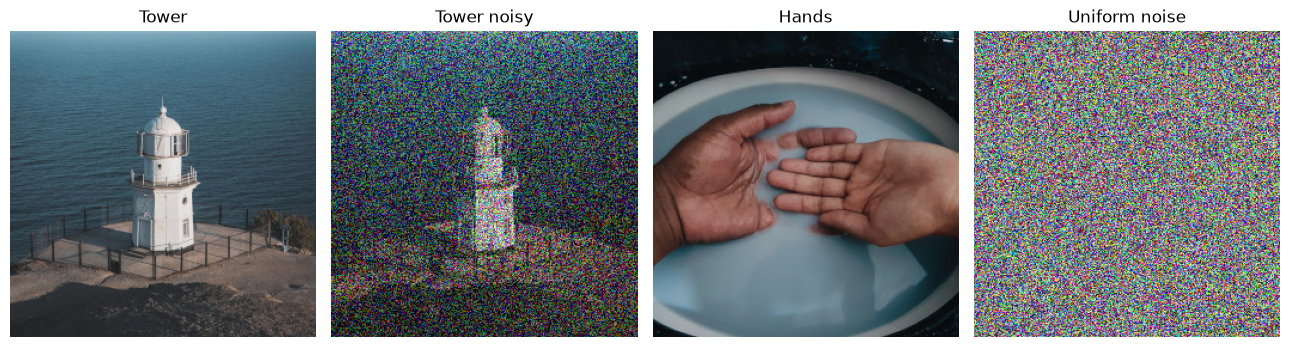

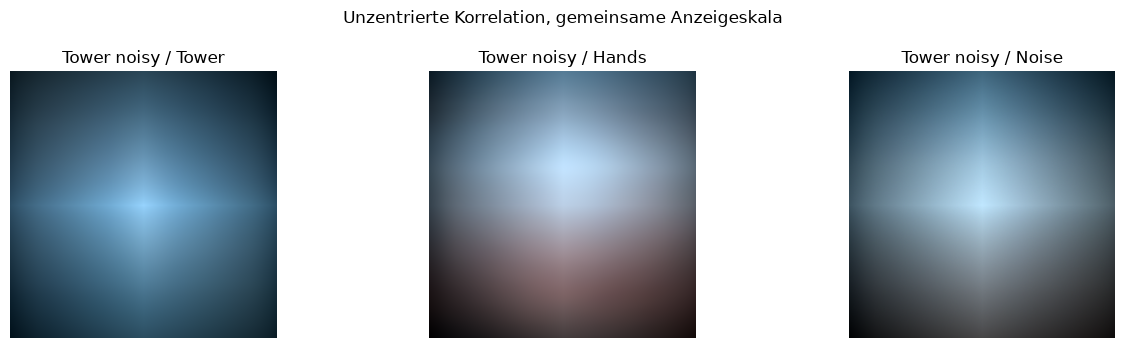

In [13]:
# Laden der Beispiele
from pathlib import Path
##------TODO-------------------
datenordner = Path("Daten") / "uebung3_daten"
tower = np.load(datenordner / "tower.npy", allow_pickle=False).astype(np.float64) / 255.0
tower_noisy = np.load(datenordner / "tower_noisy.npy", allow_pickle=False).astype(np.float64) / 255.0
hands = np.load(datenordner / "hands.npy", allow_pickle=False).astype(np.float64) / 255.0

##------TODO-------------------
# a) Gleichverteiltes Rauschen auf allen RGB-Kanälen.
rng = np.random.default_rng(42) # rng steth für random number generator, 42 ist der seed
noise = rng.uniform(0.0, 1.0, size=tower.shape) # noise wird mit rng gleichverteilt zwischen 0 und 1 erzeugt, die Größe ist die gleiche wie tower

fig, axs = plt.subplots(1,4, figsize=(13, 3.5))
axs[0].imshow(tower)
## b) Bilder plotten.----------TODO---------------
axs[1].imshow(tower_noisy)
axs[2].imshow(hands)
axs[3].imshow(noise)
for ax, titel in zip(axs, ["Tower", "Tower noisy", "Hands", "Uniform noise"]):
    ax.set_title(titel)
    ax.axis("off")
fig.tight_layout()
plt.show()

# TODO DEIN CODE HIER
# # c) Räumliche Korrelation: RGB-Kanäle getrennt behandeln.
# Ein direkter 3D-Aufruf würde zusätzlich die Farbkanalachse verschieben.
def korrelation_rgb(bild, vorlage):
    return np.stack([
        correlate(bild[..., c], vorlage[..., c], mode="same", method="fft")
        for c in range(bild.shape[2])
    ], axis=-1)

c_t_t = korrelation_rgb(tower_noisy, tower)
c_t_h = korrelation_rgb(tower_noisy, hands)
c_t_n = korrelation_rgb(tower_noisy, noise)

# Zur Visualisierung müssen wir das Ergebnis c_t_t normalisieren [0,1] zur c_t_t_p, da Matplotlib bei 3-Kanal-Bildern sonst alle Werte über 1 abschneidet

# TODO DEIN CODE HIER
# Dies ist KEINE normierte Kovarianz. Die Rohwerte bleiben unverändert.
"""korrelationen = [c_t_t, c_t_h, c_t_n]
minimum = min(karte.min() for karte in korrelationen)
maximum = max(karte.max() for karte in korrelationen)
def fuer_anzeige(karte):
    if maximum == minimum:
        return np.zeros_like(karte)
    return np.clip((karte - minimum) / (maximum - minimum), 0.0, 1.0)

c_t_t_p = fuer_anzeige(c_t_t)
c_t_h_p = fuer_anzeige(c_t_h)
c_t_n_p = fuer_anzeige(c_t_n)"""

c_t_t_p = (c_t_t - c_t_t.min()) / (c_t_t.max() - c_t_t.min())
c_t_h_p = (c_t_h - c_t_h.min()) / (c_t_h.max() - c_t_h.min())
c_t_n_p = (c_t_n - c_t_n.min()) / (c_t_n.max() - c_t_n.min())   


fig2, axs2 = plt.subplots(1,3, figsize=(13, 3.5))
axs2[0].imshow(c_t_t_p)
axs2[1].imshow(c_t_h_p)
axs2[2].imshow(c_t_n_p)
for ax, titel in zip(axs2, ["Tower noisy / Tower", "Tower noisy / Hands", "Tower noisy / Noise"]):
    ax.set_title(titel)
    ax.axis("off")
fig2.suptitle("Unzentrierte Korrelation, gemeinsame Anzeigeskala")
fig2.tight_layout()
plt.show()


In [6]:
print('normierte Kovarianz für Bild 1,2,3:', c_t_t.max(),c_t_h.max(),c_t_n.max())

print('Bild 1 Position:','y-max:',np.argmax(c_t_t[:,:,0])%256,'x-max:',np.argmax(c_t_t[:,:,0])//256)

normierte Kovarianz für Bild 1,2,3: 9210.964152249137 7242.328073817762 10219.667895624916
Bild 1 Position: y-max: 128 x-max: 128


In [14]:
from skimage.feature import match_template

vergleiche = [
    ("Tower", tower, c_t_t),
    ("Hands", hands, c_t_h),
    ("Noise", noise, c_t_n),
]

y0 = tower_noisy.shape[0] // 2
x0 = tower_noisy.shape[1] // 2

normierte_karten = {}

for name, bild, rohkarte in vergleiche:
    # Normierte Kreuzkorrelation für jeden RGB-Kanal berechnen
    karte = np.stack([
        match_template(tower_noisy[..., c], bild[..., c], pad_input=True)
        for c in range(3)
    ], axis=-1)

    normierte_karten[name] = karte

    # Pearson-Korrelation bei deckungsgleichen Bildern, gemittelt über RGB
    r = karte[y0, x0].mean()
    print(f"{name:5s} | Rohmaximum: {rohkarte.max():9.2f} | r ohne Verschiebung: {r:7.4f}")

Tower | Rohmaximum:   9210.96 | r ohne Verschiebung:  0.4283
Hands | Rohmaximum:   7242.33 | r ohne Verschiebung: -0.0913
Noise | Rohmaximum:  10219.67 | r ohne Verschiebung: -0.0038


Das Rauschbild erreicht das höchste Rohmaximum, weil die unzentrierte Korrelation auch von der Helligkeit und der überlappenden Bildfläche abhängt. Nach Zentrierung und Normierung liegt die Korrelation des Rauschbilds nahe null. Das ursprüngliche Turmbild zeigt mit \(r=0{,}4283\) die deutlichste Übereinstimmung mit tower_noisy.

## Freiwilliger Zusatz: einfache Kantendetektion

Ein kleiner Ableitungskern, beispielsweise ein Sobel-Kern, wird über das Bild geschoben. In gleichmäßig hellen Bereichen heben sich die positiven und negativen Gewichte auf; an Helligkeitssprüngen entsteht eine starke Antwort. Aus horizontalem und vertikalem Gradienten wird die Kantenstärke $\sqrt{G_x^2 + G_y^2}$ berechnet. Rauschen kann ebenfalls starke Gradienten verursachen, weshalb eine vorgeschaltete Glättung sinnvoll sein kann.

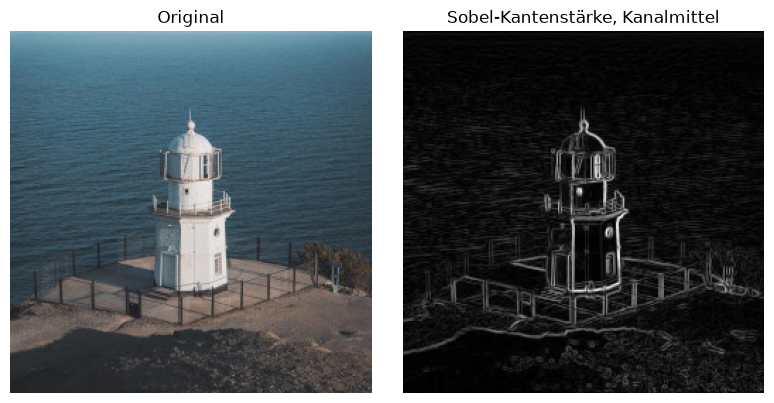

In [8]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float) # Sobel-Operator in x-Richtung
sobel_y = sobel_x.T # Sobel-Operator in y-Richtung

# --------Berechnet die Kantenstärke eines RGB-Bildes mit dem Sobel-Operator.---------
def kantenstaerke_rgb(bild): 
    erweitert = np.pad(bild, ((1, 1), (1, 1), (0, 0)), mode="reflect")
    gx = np.stack([
        correlate(erweitert[..., c], sobel_x, mode="valid", method="direct")
        for c in range(bild.shape[2])
    ], axis=-1)
    gy = np.stack([
        correlate(erweitert[..., c], sobel_y, mode="valid", method="direct")
        for c in range(bild.shape[2])
    ], axis=-1)
    return np.hypot(gx, gy)

kanten = kantenstaerke_rgb(tower) # Berechnet die Kantenstärke des Turmes
assert kanten.shape == tower.shape # Überprüft, dass die Dimensionen übereinstimmen

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].imshow(tower)
axs[0].set_title("Original")
axs[1].imshow(kanten.mean(axis=-1), cmap="gray")
axs[1].set_title("Sobel-Kantenstärke, Kanalmittel")
for ax in axs:
    ax.axis("off")
fig.tight_layout()
plt.show()

## Aufgabe 2: Naive Bayes Classifier

Reminder: Die Annahme beim Naive Bayes (NB) ist bedingte Unabhängikeit der Merkmale gegeben die Klasse. Der Vorteil, der sich daraus ergibt ist, dass wir nur skalare/univariate Verteilungsdichten schätzen müssen.

Ist diese Unabhängigkeit tatsächlich erfüllt?

Der Bayes Classifier (non-idiot Bayes) macht diese Annahme nicht. In dieser Übung wollen wir uns anschauen, welche Auswirkungen das auf das Klassifikationsergebnis hat.

Gegeben ist ein Datensatz aus zwei korrelierten Merkmalen und den zugehörigen Klassen (Datensatz b). Außerdem gibt es einen Datensatz a mit zwei unkorrelierten Merkmalen.
Vergleiche durch Plots und Berechnung der Klassifikationsergebnisse für Testdaten die beiden Klassifier (NB und non-idiot Bayes). Ihr dürft annehmen, dass die Merkmale einer Gaussverteilung folgen.

*Tipp:* In der Vorlesung lernen wir bereits eine Implementierung kennen.

*Zusatz:* Reduziere die Menge der Trainingsdaten, wie verhalten sich die beiden Classifier? Erstelle eigene Trainingsdaten mit größerer Feature-Anzahl, was beobachtest du?



Text(0.5, 1.0, 'Datensatz b')

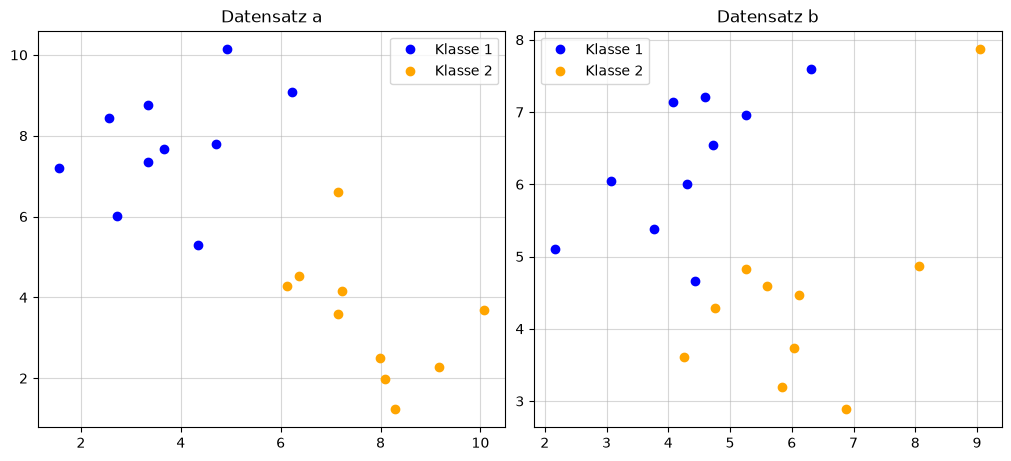

In [9]:
# Lade und plotte die Daten
# Wir haben zwei Datensätze (a und b) aus unterschiedlichen Verteilungen, in denen jeweils zwei Klassen exisitieren
from pathlib import Path
datenordner = Path("Daten") / "uebung3_daten"

with np.load(datenordner / 'data_bayes_clas.npz') as data:
  class1_a = data['class1_a']
  class2_a = data['class2_a']
  class1_a_test = data['class1_a_test'] # Unser Testdatum, von dem wir wissen, dass es zu Klasse 1 gehört
  class1_b = data['class1_b']
  class2_b = data['class2_b']
  class1_b_test = data['class1_b_test'] # Unser Testdatum, von dem wir wissen, dass es zu Klasse 1 gehört


bayes_daten = {
  "a": ((class1_a, class2_a), class1_a_test),
  "b": ((class1_b, class2_b), class1_b_test)
}

fig, (ax1,ax2) = plt.subplots(1,2, figsize=(10, 4.5), constrained_layout=True)
ax1.plot(class1_a[0,:],class1_a[1,:],'o', label='Klasse 1', color='blue')
ax1.plot(class2_a[0,:],class2_a[1,:],'o', label='Klasse 2', color='orange')
ax1.grid(alpha=0.5)
ax1.legend()
ax1.set_title('Datensatz a')
# TODO DEIN CODE HERE
ax2.plot(class1_b[0,:],class1_b[1,:],'o', label='Klasse 1', color='blue')
ax2.plot(class2_b[0,:],class2_b[1,:],'o', label='Klasse 2', color='orange')
ax2.legend()
ax2.grid(alpha=0.5)
ax2.set_title('Datensatz b')


In [10]:
# Programmiere die Classifier und Löse die Aufgabe
import numpy as np
from scipy.stats import norm, multivariate_normal
from scipy.special import logsumexp

# naiver Bayes Classifier, gibt Wahrscheinlichkeiten (oder optional logprobs) zurück für jede Klasse, man kann arg Maximum davon nehmen
def naive_bayes_classifier(train_data,test_data,is_log=False):
  '''
  train_data = Tuple[np.ndarray] : (features,samples)
  test_data = np.ndarray : (features,samples)
  '''
  n_features = train_data[0].shape[0]
  mus = list()
  sigmas = list()
  p_class = list()
  n_samples = sum([i.shape[1] for i in train_data])

  #TODO DEIN CODE HIER, die Normalverteilung kann mit norm.pdf(x,loc=mu,scale=sigma) ausgewertet werden
  test_data = np.asarray(test_data, dtype=float)
  if test_data.ndim == 1:
    test_data = test_data[:, None]

  # Kleine Untergrenze für Varianzen, damit keine Division durch null entsteht.
  var_scale = max(
      float(np.var(np.hstack(train_data), axis=1).mean()),
      1e-12
  )

  for klasse in train_data:
    mus.append(klasse.mean(axis=1))

    varianzen = klasse.var(axis=1, ddof=0)
    sigmas.append(np.sqrt(np.maximum(varianzen, 1e-9 * var_scale)))

    p_class.append(klasse.shape[1] / n_samples)

  # Bedingte Unabhängigkeit:
  # Produkt der einzelnen Merkmalsdichten = Summe ihrer Logarithmen.
  log_scores = []

  for k in range(len(train_data)):
    log_likelihood = norm.logpdf(
        test_data,
        loc=mus[k][:, None],
        scale=sigmas[k][:, None]
    ).sum(axis=0)

    log_scores.append(np.log(p_class[k]) + log_likelihood)

  log_scores = np.vstack(log_scores)

  # Über alle Klassen normieren: Evidence berücksichtigen.
  log_posterior = (
      log_scores - logsumexp(log_scores, axis=0, keepdims=True)
  )

  return log_posterior if is_log else np.exp(log_posterior)

# Bayes Classifier, gibt Wahrscheinlichkeiten (oder optional logprobs) zurück für jede Klasse, man kann arg Maximum davon nehmen
def bayes_classifier(train_data,test_data,is_log=False):
  '''
  train_data = Tuple[np.ndarray] : (features,samples)
  test_data = np.ndarray : (features,samples)
  '''
  n_features = train_data[0].shape[0]
  mus = list()
  sigmas = list()
  p_class = list()
  n_samples = sum([i.shape[1] for i in train_data])
  
  #TODO DEIN CODE HIER, die Normalverteilung kann mit norm.pdf(x,loc=mu,scale=sigma) ausgewertet werden
  test_data = np.asarray(test_data, dtype=float)
  if test_data.ndim == 1:
    test_data = test_data[:, None]

  var_scale = max(
      float(np.var(np.hstack(train_data), axis=1).mean()),
      1e-12
  )

  for klasse in train_data:
    mu = klasse.mean(axis=1)
    mus.append(mu)

    # Volle Kovarianzmatrix berücksichtigt die Merkmalsabhängigkeiten.
    zentriert = klasse - mu[:, None]
    kovarianz = zentriert @ zentriert.T / klasse.shape[1]

    # Kleine Regularisierung für numerische Stabilität.
    kovarianz += 1e-6 * var_scale * np.eye(n_features)

    # sigmas enthält hier Kovarianzmatrizen, keine Standardabweichungen.
    sigmas.append(kovarianz)
    p_class.append(klasse.shape[1] / n_samples)

  log_scores = []

  for k in range(len(train_data)):
    log_likelihood = np.atleast_1d(
        multivariate_normal.logpdf(
            test_data.T,
            mean=mus[k],
            cov=sigmas[k]
        )
    )

    log_scores.append(np.log(p_class[k]) + log_likelihood)

  log_scores = np.vstack(log_scores)

  # Über alle Klassen normieren: Evidence berücksichtigen.
  log_posterior = (
      log_scores - logsumexp(log_scores, axis=0, keepdims=True)
  )

  return log_posterior if is_log else np.exp(log_posterior)

In [11]:
# Überprüfe die Lösung der Übungsaufgabe. Was bedeutet das Ergebnis?

print('naive a:', naive_bayes_classifier((class1_a,class2_a),class1_a_test))
print('not naive a:', bayes_classifier((class1_a,class2_a),class1_a_test))
print('naive b', naive_bayes_classifier((class1_b,class2_b),class1_b_test))
print('not naive b:', bayes_classifier((class1_b,class2_b),class1_b_test))


print("\nDatensatz | Modell                  | P(Klasse 1) | Vorhersage | korrekt")
bayes_ergebnisse = []
for name, (training, testpunkt) in bayes_daten.items():
    for modellname, klassifikator in [
        ("Naive Bayes", naive_bayes_classifier),
        ("Bayes (volle Kovarianz)", bayes_classifier),
    ]:
        wahrscheinlichkeiten = klassifikator(training, testpunkt)
        vorhersage = int(np.argmax(wahrscheinlichkeiten[:, 0])) + 1
        p1 = float(wahrscheinlichkeiten[0, 0])
        bayes_ergebnisse.append((name, modellname, p1, vorhersage))
        print(f"{name:^9} | {modellname:<23} | {p1:11.6f} | {vorhersage:^10} | {vorhersage == 1}")

naive a: [[9.99354660e-01]
 [6.45339993e-04]]
not naive a: [[0.99330202]
 [0.00669798]]
naive b [[0.36453389]
 [0.63546611]]
not naive b: [[0.9087172]
 [0.0912828]]

Datensatz | Modell                  | P(Klasse 1) | Vorhersage | korrekt
    a     | Naive Bayes             |    0.999355 |     1      | True
    a     | Bayes (volle Kovarianz) |    0.993302 |     1      | True
    b     | Naive Bayes             |    0.364534 |     2      | False
    b     | Bayes (volle Kovarianz) |    0.908717 |     1      | True


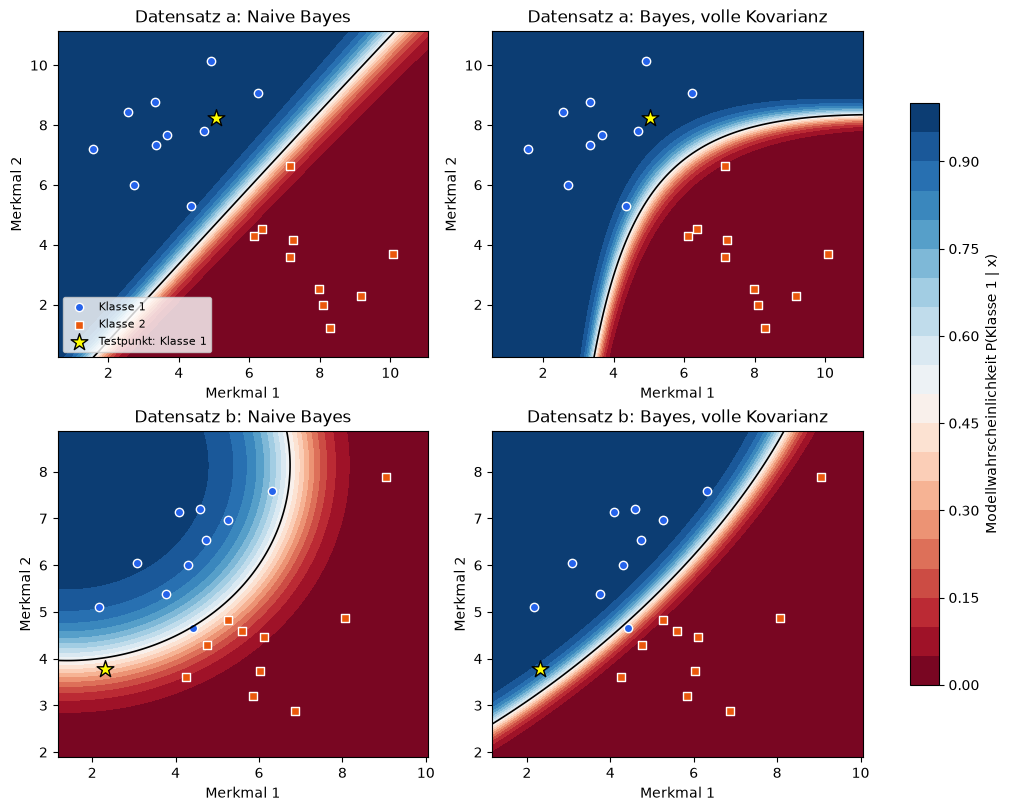

In [ ]:
# Entscheidungsgrenzen verdeutlichen den Unterschied zwischen diagonalem und vollem Modell.
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for zeile, (name, (training, testpunkt)) in enumerate(bayes_daten.items()):
    alle_punkte = np.hstack([*training, testpunkt])
    x = np.linspace(alle_punkte[0].min() - 1.0, alle_punkte[0].max() + 1.0, 160)
    y = np.linspace(alle_punkte[1].min() - 1.0, alle_punkte[1].max() + 1.0, 160)
    xx, yy = np.meshgrid(x, y)
    raster = np.vstack([xx.ravel(), yy.ravel()])
    for spalte, (modellname, klassifikator) in enumerate([
        ("Naive Bayes", naive_bayes_classifier),
        ("Bayes, volle Kovarianz", bayes_classifier),
    ]):
        ax = axes[zeile, spalte]
        p1 = klassifikator(training, raster)[0].reshape(xx.shape)
        flaeche = ax.contourf(xx, yy, p1, levels=np.linspace(0, 1, 21), cmap="RdBu", vmin=0, vmax=1)
        ax.contour(xx, yy, p1, levels=[0.5], colors="black", linewidths=1.2)
        ax.scatter(training[0][0], training[0][1], color="#2563eb", edgecolor="white", label="Klasse 1")
        ax.scatter(training[1][0], training[1][1], color="#ea580c", edgecolor="white", marker="s", label="Klasse 2")
        ax.scatter(testpunkt[0], testpunkt[1], color="yellow", edgecolor="black", marker="*", s=160,
                   label="Testpunkt: Klasse 1")
        ax.set(title=f"Datensatz {name}: {modellname}", xlabel="Merkmal 1", ylabel="Merkmal 2")
        if zeile == 0 and spalte == 0:
            ax.legend(fontsize=8, loc="lower left")
fig.colorbar(flaeche, ax=axes.ravel().tolist(), label="Modellwahrscheinlichkeit P(Klasse 1 | x)", shrink=0.8)
plt.show()

### Freiwilliger Zusatz: weniger Trainingsdaten und mehr Merkmale

Teil 1: P(Klasse 1 | einziger Testpunkt), Mittelwert +/- SD
Fall  n/Klasse  Naive Bayes       Bayes (volle Kovarianz)
   a         2  0.816 +/- 0.382   0.700 +/- 0.470
   a         3  0.950 +/- 0.224   0.950 +/- 0.224
   a         5  0.998 +/- 0.003   0.968 +/- 0.076
   a        10  0.999 +/- 0.000   0.993 +/- 0.000
   b         2  0.254 +/- 0.418   0.500 +/- 0.513
   b         3  0.246 +/- 0.402   0.425 +/- 0.494
   b         5  0.367 +/- 0.341   0.619 +/- 0.383
   b        10  0.365 +/- 0.000   0.909 +/- 0.000
SD = Streuung zwischen Teilstichproben; bei n=10 wird nur einmal gerechnet.

Teil 2: Accuracy auf unabhaengigen, ausgeglichenen Testdaten
rho  Features  Naive Bayes (%)      Bayes volle Kovarianz (%)
0.0         2  77.6 +/- 1.8         77.5 +/- 1.9
0.0        10  71.2 +/- 4.4         61.9 +/- 3.4
0.0        30  64.4 +/- 3.1         55.9 +/- 1.8
0.6         2  77.6 +/- 1.4         84.0 +/- 1.4
0.6        10  70.1 +/- 4.4         66.5 +/- 3.6
0.6        30  64.6 +/- 4.6         5

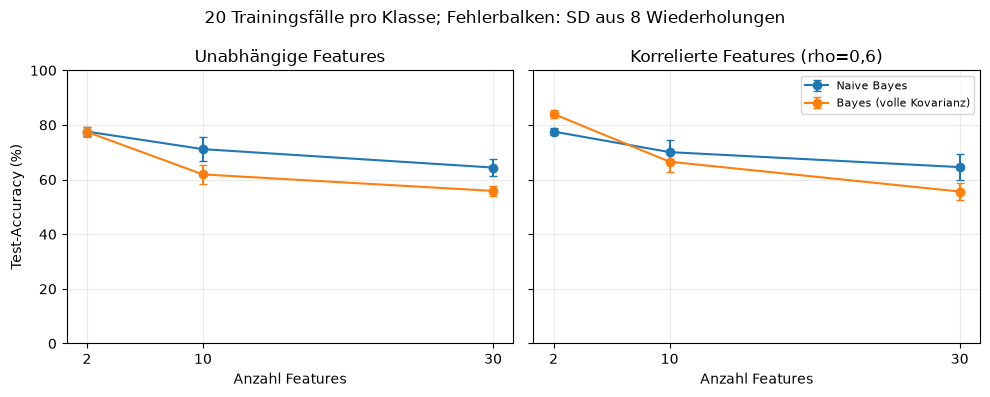

In [53]:
# Optionaler Zusatz zu Aufgabe 2.
# Nach dem Laden der Daten und den beiden Klassifikator-Funktionen ausfuehren.
import numpy as np
import matplotlib.pyplot as plt


def run_task2_extra():
    modelle = {
        "Naive Bayes": naive_bayes_classifier,
        "Bayes (volle Kovarianz)": bayes_classifier,
    }
    rng_teilmengen = np.random.default_rng(2026)

    # 1. Weniger Trainingsdaten: immer derselbe bekannte Testpunkt aus Klasse 1.
    # Die ausgegebenen Werte sind Modellwahrscheinlichkeiten, keine Accuracy.
    print("Teil 1: P(Klasse 1 | einziger Testpunkt), Mittelwert +/- SD")
    print("Fall  n/Klasse  Naive Bayes       Bayes (volle Kovarianz)")
    daten = {
        "a": ((class1_a, class2_a), class1_a_test),
        "b": ((class1_b, class2_b), class1_b_test),
    }
    for name, (training, testpunkt) in daten.items():
        for n in (2, 3, 5, 10):
            wiederholungen = 1 if n == 10 else 20
            werte = {modell: [] for modell in modelle}
            for _ in range(wiederholungen):
                teiltraining = tuple(
                    klasse[:, rng_teilmengen.choice(klasse.shape[1], n, replace=False)]
                    for klasse in training
                )
                for modell, klassifikator in modelle.items():
                    # Erste Zeile entspricht der ersten Trainingsklasse (Klasse 1).
                    werte[modell].append(float(klassifikator(teiltraining, testpunkt)[0, 0]))
            ausgabe = []
            for modell in modelle:
                p = np.asarray(werte[modell])
                sd = p.std(ddof=1) if wiederholungen > 1 else 0.0
                ausgabe.append(f"{p.mean():.3f} +/- {sd:.3f}")
            print(f"{name:>4}  {n:>8}  {ausgabe[0]:<17} {ausgabe[1]}")
    print("SD = Streuung zwischen Teilstichproben; bei n=10 wird nur einmal gerechnet.")

    # 2. Mehr Features: frische Trainings- und Testdaten in jeder Wiederholung.
    # Der Mittelwert unterscheidet sich nur im ersten Feature. Bei rho > 0
    # helfen die anderen Features, dessen korreliertes Rauschen einzuschaetzen.
    rng_simulation = np.random.default_rng(2027)
    dimensionen = (2, 10, 30)
    n_train, n_test, wiederholungen = 20, 500, 8  # jeweils pro Klasse
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    print("\nTeil 2: Accuracy auf unabhaengigen, ausgeglichenen Testdaten")
    print("rho  Features  Naive Bayes (%)      Bayes volle Kovarianz (%)")

    for ax, rho in zip(axes, (0.0, 0.6)):
        ergebnisse = {modell: [] for modell in modelle}
        for d in dimensionen:
            abstand = np.abs(np.arange(d)[:, None] - np.arange(d)[None, :])
            kovarianz = np.eye(d) if rho == 0 else rho ** abstand
            mittelwerte = np.zeros((2, d))
            mittelwerte[:, 0] = (-0.8, 0.8)
            scores = {modell: [] for modell in modelle}
            for _ in range(wiederholungen):
                training = tuple(
                    rng_simulation.multivariate_normal(mu, kovarianz, n_train).T
                    for mu in mittelwerte
                )
                test = np.hstack([
                    rng_simulation.multivariate_normal(mu, kovarianz, n_test).T
                    for mu in mittelwerte
                ])
                ziel = np.repeat(np.arange(2), n_test)
                for modell, klassifikator in modelle.items():
                    vorhersage = np.argmax(klassifikator(training, test), axis=0)
                    scores[modell].append(np.mean(vorhersage == ziel))
            for modell in modelle:
                ergebnisse[modell].append(scores[modell])
            ausgabe = [
                f"{100*np.mean(scores[m]):.1f} +/- {100*np.std(scores[m], ddof=1):.1f}"
                for m in modelle
            ]
            print(f"{rho:.1f}  {d:>8}  {ausgabe[0]:<20} {ausgabe[1]}")

        for modell in modelle:
            scores = np.asarray(ergebnisse[modell])  # Features x Wiederholungen
            ax.errorbar(
                dimensionen, 100*scores.mean(axis=1),
                yerr=100*scores.std(axis=1, ddof=1),
                marker="o", capsize=3, label=modell,
            )
        ax.set(title=f"Unabhängige Features" if rho == 0 else "Korrelierte Features (rho=0,6)",
               xlabel="Anzahl Features", xticks=dimensionen, ylim=(0, 100))
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("Test-Accuracy (%)")
    axes[1].legend(fontsize=8)
    fig.suptitle("20 Trainingsfälle pro Klasse; Fehlerbalken: SD aus 8 Wiederholungen")
    fig.tight_layout()
    plt.show()


run_task2_extra()

## Aufgabe 3: Zentraler Grenzwertsatz

Die Wahrscheinlichkeit im Laufe des Lebens an Lungenkrebs zu erkranken beträgt für Frauen in den USA 6%. Pro Tag werden etwa 5000 weibliche Babys auf die Welt gebracht. Wie sieht die Wahrscheinlichkeitsverteilung aus, wenn wir betrachten wollen, wieviele der  am heutigen Tag geborenen Frauen im Laufe ihres Lebens an Lungenkrebs erkranken werden?


a) Simuliere die Häufigkeit, wobei du jede Person berücksichtigst. Plotte das Histogramm.

b) Was sagt der Zentrale Grenzwertsatz aus? Können wir das Ergebnis durch eine parametrierte Funktion annähern? Wie lassen sich die Parameter berechnen?

Quelle https://de.statista.com/statistik/daten/studie/457384/umfrage/usa-wahrscheinlichkeit-der-entwicklung-von-lungenkrebs/


Theoretischer Erwartungswert: 300.0
Theoretische Varianz: 282.0
Theoretische Standardabweichung: 16.793
Simulierter Mittelwert: 300.108
Simulierte Standardabweichung: 16.665


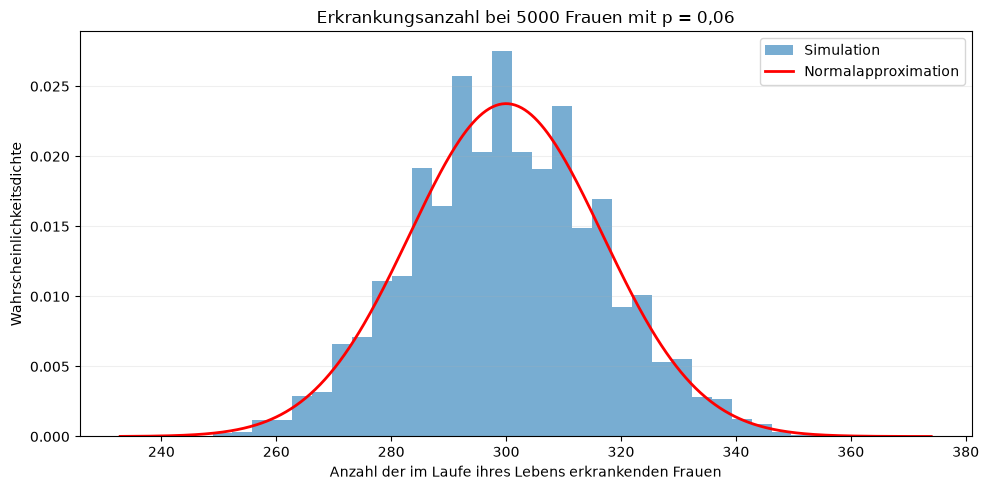

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

p = 0.06
n_frauen = 5000
n_samples = 10000  # Anzahl simulierter Gruppen mit jeweils 5000 Frauen

# a) Für jede Person simulieren, ob sie im Laufe ihres Lebens erkrankt.
rng = np.random.default_rng(42)
anzahl_erkrankungen = np.empty(n_samples, dtype=int)

# Blockweise simulieren, um Arbeitsspeicher zu sparen.
batch_size = 250

for start in range(0, n_samples, batch_size):
    ende = min(start + batch_size, n_samples)

    erkrankt = rng.random((ende - start, n_frauen)) < p
    anzahl_erkrankungen[start:ende] = erkrankt.sum(axis=1)

# b) Parameter der Normalapproximation
mu = n_frauen * p
varianz = n_frauen * p * (1 - p)
sigma = np.sqrt(varianz)

print("Theoretischer Erwartungswert:", mu)
print("Theoretische Varianz:", varianz)
print("Theoretische Standardabweichung:", round(sigma, 3))
print("Simulierter Mittelwert:", round(anzahl_erkrankungen.mean(), 3))
print(
    "Simulierte Standardabweichung:",
    round(anzahl_erkrankungen.std(ddof=1), 3)
)

# Histogramm und approximierende Normaldichte
x = np.linspace(
    min(anzahl_erkrankungen.min(), mu - 4 * sigma),
    max(anzahl_erkrankungen.max(), mu + 4 * sigma),
    500
)

plt.figure(figsize=(10, 5))

plt.hist(
    anzahl_erkrankungen,
    bins=40,
    density=True,
    alpha=0.6,
    label="Simulation"
)

plt.plot(
    x,
    norm.pdf(x, loc=mu, scale=sigma),
    color="red",
    linewidth=2,
    label="Normalapproximation"
)

plt.xlabel("Anzahl der im Laufe ihres Lebens erkrankenden Frauen")
plt.ylabel("Wahrscheinlichkeitsdichte")
plt.title("Erkrankungsanzahl bei 5000 Frauen mit p = 0,06")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()